# Machine Learning — Practical Session 1: Python for Data Exploration and Preprocessing
**National Higher School of Advanced Technologies (ENST)**  
*Academic Year: 2026–2027*  
**Student:** Anes Benrahmoune  
**Level:** 4th Year Student (Artificial Intelligence Specialty)  
**Group:** Group 1  
**GitHub:** [BENRAHMOUNEANES](https://github.com/BENRAHMOUNEANES)  
**Course:** Machine Learning  

---

## Learning Objectives
By the end of this practical session, we demonstrate how to:
1. Load, inspect, and partition tabular datasets using pandas and scikit-learn.
2. Read, explore, and analyze text datasets using standard Python I/O and scikit-learn's 20 Newsgroups benchmark.
3. Detect, visualize, and remediate missing data with appropriate statistical imputation strategies while guarding against data leakage.
4. Scale numerical features, perform binarization, and encode categorical variables using ordinal and one-hot representations.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn utilities
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_20newsgroups
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    MaxAbsScaler,
    RobustScaler,
    normalize,
    Binarizer,
    OrdinalEncoder,
    OneHotEncoder,
    LabelEncoder
)

# Plotting aesthetics
%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.autolayout': True, 'font.sans-serif': 'DejaVu Sans', 'font.size': 10})

# Resolve dataset paths relative to current execution environment
DATA_DIR = "data"
print(f"Data directory:    {DATA_DIR}")


Data directory:    data


---
## Exercise 1 — Exploring a Tabular Dataset and Creating Data Splits
**Dataset:** `Iris_Dataset.csv`

The Iris dataset contains morphological measurements of 150 iris flowers across three distinct species (*Iris-setosa*, *Iris-versicolor*, and *Iris-virginica*).


In [3]:
# 1. Load CSV file into a pandas DataFrame named D
iris_path = os.path.join(DATA_DIR, "Iris_Dataset.csv")
D = pd.read_csv(iris_path)

# 2. Inspect the dataset
print("--- DataFrame info() ---")
D.info()

print("\n--- DataFrame shape ---")
print(f"Shape: {D.shape[0]} rows, {D.shape[1]} columns")

print("\n--- Columns ---")
print(list(D.columns))

print("\n--- First 5 rows (head) ---")
display(D.head())

print("\n--- Summary Statistics (describe) ---")
display(D.describe().round(3))

--- DataFrame info() ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

--- DataFrame shape ---
Shape: 150 rows, 5 columns

--- Columns ---
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

--- First 5 rows (head) ---


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa



--- Summary Statistics (describe) ---


,sepal_length,sepal_width,petal_length,petal_width
count,150.000,150.000,150.000,150.000
mean,5.843,3.054,3.759,1.199
std,0.828,0.434,1.764,0.763
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


### Explanation of Inspection Methods:
- `info()`: Reveals the DataFrame index range, column names, memory consumption (~7.9 KB), non-null counts (150 non-null values across all columns, confirming no initial missing data), and data types (4 `float64` numerical attributes and 1 object/string column).
- `describe()`: Summarizes parametric and non-parametric descriptive statistics: central tendency (`mean`), dispersion (`std`), range (`min`, `max`), and quartiles (`25%`, `50%` median, `75%`). Notice `petal_length` exhibits high dispersion (std = 1.764) compared to `sepal_width` (std = 0.434).
- `shape`: (150, 5), indicating 150 independent biological observations described by 5 feature vectors.
- `columns`: Returns index of column identifiers: `['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']`.
- `head()`: Displays top 5 observations, confirming measurements are in centimeters and classes are properly formatted strings.


In [4]:
# 3. Select features sepal_length and petal_width into a new DataFrame
selected_df = D[["sepal_length", "petal_width"]]

# 4. Display the first 20 observations
print("First 20 observations of sepal_length and petal_width:")
display(selected_df.head(20))

# 5. Create a defensive copy of original DataFrame
D_copy = D.copy()
print("Original DataFrame copied successfully into `D_copy`.")

First 20 observations of sepal_length and petal_width:


,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


Original DataFrame copied successfully into `D_copy`.


### Why is creating a copy useful?
When developing machine learning preprocessing pipelines, transformations such as imputation, outlier clipping, or feature scaling mutate in-memory arrays. Working on a deep copy (`D.copy()`):
1. **Preserves raw ground-truth data:** Enables auditing, baseline comparisons, and reproducible re-execution without reloading from disk.
2. **Eliminates `SettingWithCopyWarning`:** Chained indexing or slicing views in pandas can cause unintended mutations or silent failures; deep copies guarantee independent memory allocation.


In [5]:
# 6 & 7. Split data into training (80%) and test (20%) sets with stratification
X = D.drop(columns=["species"])
y = D["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 8. Verify number and proportion of observations
total_obs = len(D)
print("=== Split Verification ===")
print(f"Total observations: {total_obs}")
print(f"Training set count: {len(X_train)} ({len(X_train)/total_obs*100:.1f}%)")
print(f"Test set count:     {len(X_test)} ({len(X_test)/total_obs*100:.1f}%)")

print("\n=== Class Proportions in Training Set ===")
display(y_train.value_counts(normalize=True).to_frame(name="Train Proportion"))

print("\n=== Class Proportions in Test Set ===")
display(y_test.value_counts(normalize=True).to_frame(name="Test Proportion"))

=== Split Verification ===
Total observations: 150
Training set count: 120 (80.0%)
Test set count:     30 (20.0%)

=== Class Proportions in Training Set ===


,Train Proportion
species,
Iris-setosa,0.333333
Iris-virginica,0.333333
Iris-versicolor,0.333333



=== Class Proportions in Test Set ===


,Test Proportion
species,
Iris-setosa,0.333333
Iris-virginica,0.333333
Iris-versicolor,0.333333


> ### Discussion: Why must the test set be kept separate until final evaluation?
>
> 1. **Prevention of Data Leakage (Lookahead / Snooping Bias):** If test observations participate in preprocessing (e.g., computing global mean/standard deviation for `StandardScaler`, identifying global medians for imputation, or picking top features), parameters of the test distribution contaminate the training process. The model indirectly 'cheats' by learning statistical properties of future data.
> 2. **Unbiased Generalization Estimate:** The sole purpose of a test set is to simulate real-world, unseen production data. If test data leaks into model selection or hyperparameter tuning, validation scores become artificially optimistic, resulting in degraded real-world performance.


---
## Exercise 2 — Exploring Text Data
**Files:** `txt_file.txt` and scikit-learn's `20 Newsgroups` dataset.


In [6]:
# 1 & 2. Open txt_file.txt with UTF-8 encoding and iterate displaying each line
txt_path = os.path.join(DATA_DIR, "txt_file.txt")
print(f"Reading text file: {txt_path}\n")

with open(txt_path, "r", encoding="utf-8") as f:
    for idx, line in enumerate(f, start=1):
        # rstrip removes trailing newline characters ('\n', '\r')
        clean_line = line.rstrip("\r\n")
        print(f"Line {idx}: {clean_line}")

Reading text file: data\txt_file.txt

Line 1: 0.50,0.20,0.84,0.01,c1
Line 2: 0.10,0.10,0.40,0.02,c2
Line 3: 0.15,0.10,0.45,0.03,c2
Line 4: 0.22,0.20,0.90,0.01,c1
Line 5: 0.25,0.20,0.87,0.01,c1
Line 6: 0.10,0.10,0.38,0.02,c2


In [7]:
# 3. Load 20 Newsgroups training dataset
print("Loading 20 Newsgroups training subset...")
newsgroups_train = fetch_20newsgroups(subset="train")

# 4. Display dimensions and explain meaning
n_docs = len(newsgroups_train.data)
n_labels = len(newsgroups_train.target)
n_categories = len(newsgroups_train.target_names)

print(f"Number of documents: {n_docs}")
print(f"Number of target labels: {n_labels}")
print(f"Number of unique categories: {n_categories}")

# 5. Display first document and inspect associated label
first_target = newsgroups_train.target[0]
first_category_name = newsgroups_train.target_names[first_target]

print(f"\n--- First Document Associated Target ---")
print(f"Target index: {first_target}")
print(f"Category:     {first_category_name}")
print(f"\nDocument excerpt (first 350 chars):\n{'='*50}")
print(newsgroups_train.data[0][:350].strip())
print("="*50)

# 6. Display class names
print("\n--- Available Class Names (20 newsgroups) ---")
for i, name in enumerate(newsgroups_train.target_names):
    print(f"  [{i:2d}] {name}")

Loading 20 Newsgroups training subset...
Number of documents: 11314
Number of target labels: 11314
Number of unique categories: 20

--- First Document Associated Target ---
Target index: 7
Category:     rec.autos

Document excerpt (first 350 chars):
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bric

--- Available Class Names (20 newsgroups) ---
  [ 0] alt.atheism
  [ 1] comp.graphics
  [ 2] comp.os.ms-windows.misc
  [ 3] comp.sys.ibm.pc.hardware
  [ 4] comp.sys.mac.hardware
  [ 5] comp.windows.x
  [ 6] misc.forsale
  [ 7] rec.autos
  [ 8] rec.motorcycles
  [ 9] rec.sport.baseball
  [10] rec.sport.hockey
  [11] sci.crypt
  [12] sci.electronics
  [13] sci.med
  [14] sci.space
  [15] soc.relig

=== Document Length Statistics (Characters) ===
Min length:    125
Max length:    75,154
Mean length:   1,949.3
Median length: 1,178.0


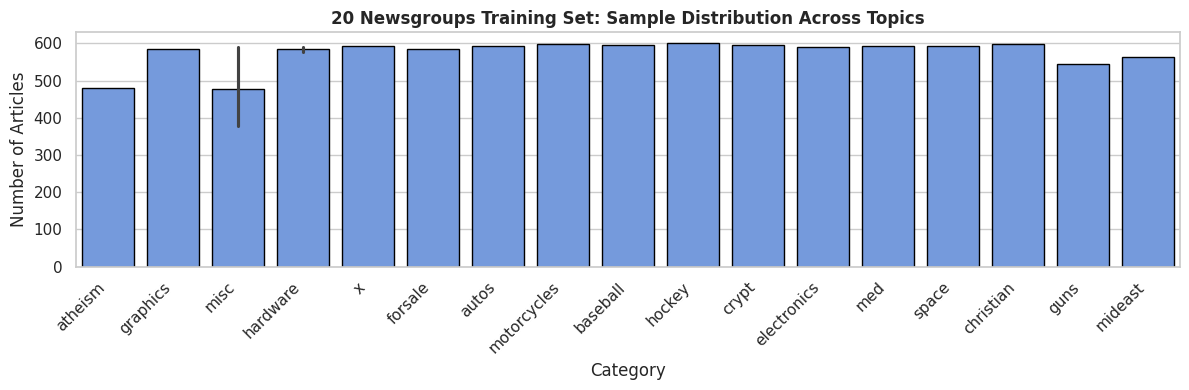

In [8]:
# 7. Optional Extension: Document length distribution and class counts
doc_lengths = [len(doc) for doc in newsgroups_train.data]

print("=== Document Length Statistics (Characters) ===")
print(f"Min length:    {np.min(doc_lengths):,}")
print(f"Max length:    {np.max(doc_lengths):,}")
print(f"Mean length:   {np.mean(doc_lengths):,.1f}")
print(f"Median length: {np.median(doc_lengths):,.1f}")

# Plot class frequency distribution
plt.figure(figsize=(12, 4))
counts = pd.Series(newsgroups_train.target).value_counts().sort_index()
short_names = [name.split('.')[-1] for name in newsgroups_train.target_names]

sns.barplot(x=short_names, y=counts.values, color="cornflowerblue", edgecolor="black")
plt.title("20 Newsgroups Training Set: Sample Distribution Across Topics", fontweight="bold")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45, ha='right')
plt.show()

---
## Exercise 3 — Detecting and Handling Missing Values
**Dataset:** `employees.csv`

Real-world datasets frequently contain missing observations resulting from non-responses, instrumentation failures, or legacy data entry habits.


Employees dataset shape: (1000, 8)

--- Data Types & Column Summary ---


,Dtype
First Name,str
Gender,str
Start Date,str
Last Login Time,str
Salary,int64
Bonus %,float64
Senior Management,object
Team,str



--- First 3 Rows ---


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance



--- Missing Value Counts (isna().sum()) ---


,Missing Count
First Name,67
Gender,145
Start Date,0
Last Login Time,0
Salary,0
Bonus %,0
Senior Management,67
Team,43


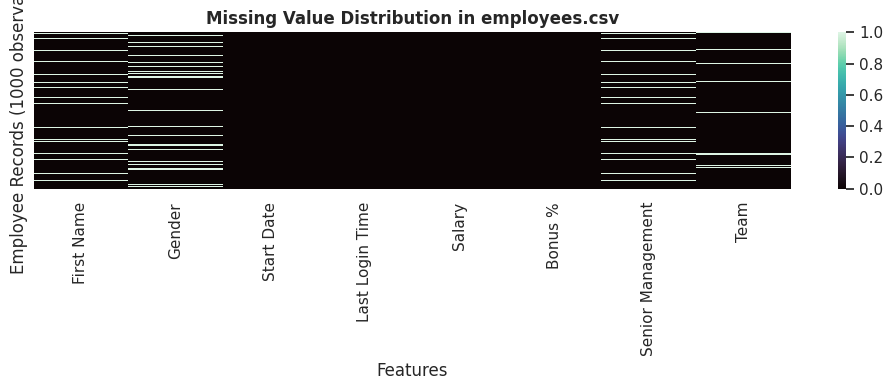

In [9]:
# 1. Load employees.csv into a DataFrame and inspect
emp_path = os.path.join(DATA_DIR, "employees.csv")
df_emp = pd.read_csv(emp_path)

print(f"Employees dataset shape: {df_emp.shape}")
print("\n--- Data Types & Column Summary ---")
display(df_emp.dtypes.to_frame(name="Dtype"))

print("\n--- First 3 Rows ---")
display(df_emp.head(3))

# 2. Count missing values in each column
print("\n--- Missing Value Counts (isna().sum()) ---")
missing_original = df_emp.isna().sum()
display(missing_original.to_frame(name="Missing Count"))

# 3. Visualize missing-value patterns using a seaborn heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(df_emp.isna(), cbar=True, cmap="mako", yticklabels=False)
plt.title("Missing Value Distribution in employees.csv", fontsize=12, fontweight="bold")
plt.xlabel("Features")
plt.ylabel("Employee Records (1000 observations)")
plt.show()

In [10]:
# 4. Create a copy and append one synthetic row containing 8 fields with custom markers
df_emp_copy = df_emp.copy()

synthetic_row = {
    "First Name": "-",
    "Gender": "na",
    "Start Date": "N/A",
    "Last Login Time": "?",
    "Salary": np.nan,
    "Bonus %": np.nan,
    "Senior Management": "None",
    "Team": "-"
}

df_emp_copy = pd.concat([df_emp_copy, pd.DataFrame([synthetic_row])], ignore_index=True)
print(f"Appended synthetic row at index {len(df_emp_copy)-1}:")
display(df_emp_copy.tail(2))

# 5. Recount missing values
print("\n--- Recounting Missing Values with Default isna() ---")
missing_after_synthetic = df_emp_copy.isna().sum()
display(missing_after_synthetic.to_frame(name="Missing After Synthetic"))

Appended synthetic row at index 1000:


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
999,Albert,Male,5/15/2012,6:24 PM,129949.0,10.169,True,Sales
1000,-,na,N/A,?,NaN,NaN,None,-



--- Recounting Missing Values with Default isna() ---


,Missing After Synthetic
First Name,67
Gender,145
Start Date,0
Last Login Time,0
Salary,1
Bonus %,1
Senior Management,67
Team,43


### Why are `'-'` and `'na'` not automatically treated as missing?
Pandas parses input text strings literally unless configured via `na_values`. Since `'-'`, `'na'`, `'?'`, and `'None'` are valid string objects (`str`), pandas assigns them non-null status. By default, `isna()` only flags standard null sentinels: `np.nan`, `None`, `<NA>`, or `NaT`.


--- Missing Values After Standardizing Placeholders to np.nan ---


,Missing Post-Replacement
First Name,68
Gender,146
Start Date,1
Last Login Time,1
Salary,1
Bonus %,1
Senior Management,68
Team,44



--- Comparison Before and After Preprocessing (Original 1000 Rows) ---


,Original Missing,Standardized Custom Nulls,Post-Imputation Missing
Bonus %,0,1.0,0
First Name,67,68.0,67
Gender,145,146.0,0
Last Login Time,0,1.0,0
Salary,0,1.0,0
Senior Management,67,68.0,0
Start Date,0,1.0,0
Team,43,NaN,0


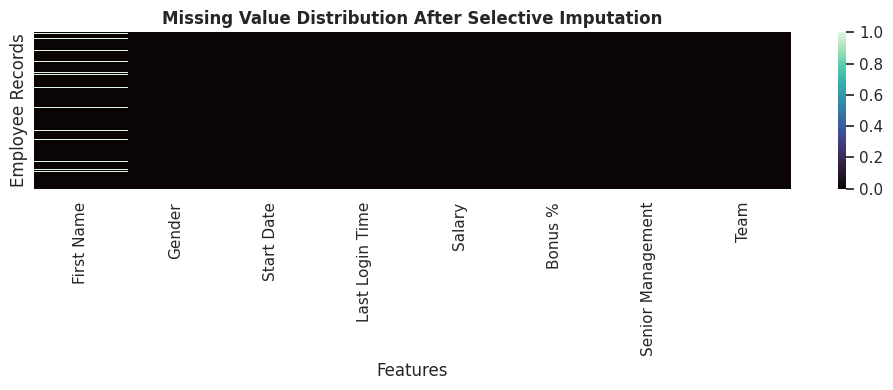

In [11]:
# 6. Convert custom placeholders to np.nan using a documented rule
custom_markers = ["-", "na", "N/A", "?", "None", "missing", "null", "NULL"]
df_emp_copy.replace(custom_markers, np.nan, inplace=True)

print("--- Missing Values After Standardizing Placeholders to np.nan ---")
missing_standardized = df_emp_copy.isna().sum()
display(missing_standardized.to_frame(name="Missing Post-Replacement"))

# 7. Apply sklearn.impute.SimpleImputer with justified domain strategies
# - Categorical features: 'most_frequent' (mode imputation)
# - Numerical continuous features: 'median' (resistant to extreme salary/bonus skewness)
# - Identifiers ('First Name', 'Start Date', 'Last Login Time'): NOT imputed

cat_features = ["Gender", "Senior Management", "Team"]
num_features = ["Salary", "Bonus %"]

cat_imputer = SimpleImputer(strategy="most_frequent")
df_emp_copy[cat_features] = cat_imputer.fit_transform(df_emp_copy[cat_features])

num_imputer = SimpleImputer(strategy="median")
df_emp_copy[num_features] = num_imputer.fit_transform(df_emp_copy[num_features])

# 8. Compare missing value counts before and after preprocessing
print("\n--- Comparison Before and After Preprocessing (Original 1000 Rows) ---")
comparison_table = pd.DataFrame({
    "Original Missing": missing_original,
    "Standardized Custom Nulls": missing_standardized[:-1],
    "Post-Imputation Missing": df_emp_copy.iloc[:-1].isna().sum()
})
display(comparison_table)

# Post-imputation heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(df_emp_copy.isna(), cbar=True, cmap="mako", yticklabels=False)
plt.title("Missing Value Distribution After Selective Imputation", fontsize=12, fontweight="bold")
plt.xlabel("Features")
plt.ylabel("Employee Records")
plt.show()

### Limitations of Imputation:
1. **Variance Shrinkage:** Imputing missing values with univariate statistics (mean/median/mode) artificially concentrates data density at a single point, underestimating sample variance.
2. **Correlation Distortion:** Single-variable imputation ignores cross-feature covariance structures, weakening true relationships between predictors.
3. **Overconfidence:** Downstream estimators treat imputed figures with identical confidence as observed ground truth, failing to propagate imputation uncertainty.
4. **Data Leakage Risk:** Imputers fitted on the entire dataset leak test/validation statistics into training features; imputers must always be fitted *solely* on training splits (`fit_transform` on train, `transform` on test).


---
## Exercise 4 — Feature Scaling, Binarization, and Categorical Encoding

### Part A. Scaling and Binarization
We evaluate feature transformation methods on the numerical matrix:
$$\mathbf{X} = \begin{pmatrix} 1 & -1 & 2 \\ 2 & 0 & 0 \\ 0 & 1 & -1 \end{pmatrix}$$


In [12]:
# Define numerical matrix
X_matrix = np.array([
    [1.0, -1.0,  2.0],
    [2.0,  0.0,  0.0],
    [0.0,  1.0, -1.0]
])
feat_cols = ["Feature 1", "Feature 2", "Feature 3"]

# 1. Apply scalers and normalize
std_scaled = StandardScaler().fit_transform(X_matrix)
minmax_scaled = MinMaxScaler().fit_transform(X_matrix)
maxabs_scaled = MaxAbsScaler().fit_transform(X_matrix)
robust_scaled = RobustScaler().fit_transform(X_matrix)
normalized = normalize(X_matrix, norm="l2")

# 2. Display transformed matrices
print("--- Original Matrix ---")
display(pd.DataFrame(X_matrix, columns=feat_cols))

print("\n--- StandardScaler (mean=0, std=1) ---")
display(pd.DataFrame(std_scaled, columns=feat_cols).round(4))

print("\n--- MinMaxScaler (bounded [0, 1]) ---")
display(pd.DataFrame(minmax_scaled, columns=feat_cols).round(4))

print("\n--- MaxAbsScaler (bounded [-1, 1], preserves sparsity) ---")
display(pd.DataFrame(maxabs_scaled, columns=feat_cols).round(4))

print("\n--- RobustScaler (median-centered, IQR scaled) ---")
display(pd.DataFrame(robust_scaled, columns=feat_cols).round(4))

print("\n--- normalize (L2 sample norm: ||x||_2 = 1) ---")
display(pd.DataFrame(normalized, columns=feat_cols).round(4))

# 4. Binarize with threshold = 0.0
binarizer = Binarizer(threshold=0.0)
X_bin = binarizer.fit_transform(X_matrix)
print("\n--- Binarized Matrix (threshold = 0.0: x > 0 -> 1, x <= 0 -> 0) ---")
display(pd.DataFrame(X_bin, columns=feat_cols, dtype=int))

--- Original Matrix ---


,Feature 1,Feature 2,Feature 3
0,1.0,-1.0,2.0
1,2.0,0.0,0.0
2,0.0,1.0,-1.0



--- StandardScaler (mean=0, std=1) ---


,Feature 1,Feature 2,Feature 3
0,0.0000,-1.2247,1.3363
1,1.2247,0.0000,-0.2673
2,-1.2247,1.2247,-1.0690



--- MinMaxScaler (bounded [0, 1]) ---


...

,Feature 1,Feature 2,Feature 3
0,0.0,-1.0,1.3333
1,1.0,0.0,0.0000
2,-1.0,1.0,-0.6667



--- normalize (L2 sample norm: ||x||_2 = 1) ---


,Feature 1,Feature 2,Feature 3
0,0.4082,-0.4082,0.8165
1,1.0000,0.0000,0.0000
2,0.0000,0.7071,-0.7071



--- Binarized Matrix (threshold = 0.0: x > 0 -> 1, x <= 0 -> 0) ---


,Feature 1,Feature 2,Feature 3
0,1,0,1
1,1,0,0
2,0,1,0


### 3. Scaling vs. Normalization:
- **Feature Scaling (Column-wise):** `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`, and `RobustScaler` compute summary statistics down each column across all instances. They align feature ranges so that broad-magnitude attributes do not dominate distance or gradient computations.
- **Sample Normalization (Row-wise):** `normalize` operates horizontally across features for a single sample, scaling each feature vector to unit norm (e.g., Euclidean length 1). It is primarily used in text mining, cosine similarity matching, and directional clustering.

> ### Discussion: Why does scaling matter for KNN, SVMs, and Gradient-based models? Is it needed for Decision Trees?
> - **K-Nearest Neighbors (KNN):** KNN calculates distance metrics ($L_2 = \sqrt{\sum (u_i - v_i)^2}$). An unscaled attribute with range $[0, 100,000]$ will completely overpower an attribute in range $[0, 1]$, making the distance metric univariate.
> - **Support Vector Machines (SVM):** SVMs maximize the geometric margin separating hyperplanes. Unscaled variables bias the optimization toward high-variance coordinates, distorting kernel inner products ($K(u, v) = \exp(-\gamma ||u - v||^2)$).
> - **Gradient Descent:** Unequal feature scales produce elongated elliptical loss contours with high condition numbers. Gradients oscillate perpendicular to steep ravines rather than moving toward the optimum, requiring tiny learning rates.
> - **Decision Trees:** Decision trees are **scale-invariant**. Tree splits are determined by thresholding individual features monotonically ($x_j \le \theta$). Any strictly monotonic transformation preserves rank order, leaving optimal split thresholds and tree architecture completely unchanged.


In [13]:
# Part B: Categorical Dataset
cat_df = pd.DataFrame({
    "Feature 1": ["male", "female", "female", "male"],
    "Feature 2": ["from US", "from Europe", "from Asia", "from Africa"],
    "Feature 3": ["uses Safari", "uses Safari", "uses Firefox", "uses Chrome"],
    "Target": ["US", "France", "Japan", "Algeria"]
})
print("--- Categorical Input Dataset ---")
display(cat_df)

# 1. OrdinalEncoder on the three input features
ord_enc = OrdinalEncoder()
X_ordinal = ord_enc.fit_transform(cat_df[["Feature 1", "Feature 2", "Feature 3"]])

print("\n--- OrdinalEncoded Input Features ---")
display(pd.DataFrame(X_ordinal, columns=["Feature 1", "Feature 2", "Feature 3"], dtype=int))

print("\nLearned Feature Categories:")
for col, cats in zip(["Feature 1", "Feature 2", "Feature 3"], ord_enc.categories_):
    print(f"  {col}: {list(cats)}")

# 2. LabelEncoder on target variable
lbl_enc = LabelEncoder()
y_lbl = lbl_enc.fit_transform(cat_df["Target"])

print("\n--- LabelEncoded Target Variable ---")
for code, name in enumerate(lbl_enc.classes_):
    print(f"  Class '{name}' -> Numeric Code {code}")
print(f"Encoded vector: {y_lbl}")

# 3. OneHotEncoder on target variable
ohe = OneHotEncoder(sparse_output=False)
y_ohe = ohe.fit_transform(cat_df[["Target"]])

print("\n--- OneHotEncoded Target Variable (Binary Matrix) ---")
display(pd.DataFrame(y_ohe, columns=ohe.categories_[0], dtype=int))

--- Categorical Input Dataset ---


,Feature 1,Feature 2,Feature 3,Target
0,male,from US,uses Safari,US
1,female,from Europe,uses Safari,France
2,female,from Asia,uses Firefox,Japan
3,male,from Africa,uses Chrome,Algeria



--- OrdinalEncoded Input Features ---


,Feature 1,Feature 2,Feature 3
0,1,3,2
1,0,2,2
2,0,1,1
3,1,0,0



Learned Feature Categories:
  Feature 1: ['female', 'male']
  Feature 2: ['from Africa', 'from Asia', 'from Europe', 'from US']
  Feature 3: ['uses Chrome', 'uses Firefox', 'uses Safari']

--- LabelEncoded Target Variable ---
  Class 'Algeria' -> Numeric Code 0
  Class 'France' -> Numeric Code 1
  Class 'Japan' -> Numeric Code 2
  Class 'US' -> Numeric Code 3
Encoded vector: [3 1 2 0]

--- OneHotEncoded Target Variable (Binary Matrix) ---


,Algeria,France,Japan,US
0,0,0,0,1
1,0,1,0,0
2,0,0,1,0
3,1,0,0,0


### 4. Why One-Hot Encoding is preferable for Nominal Features:
- **Integer / Ordinal Encoding:** Assigns sequential integers ($0, 1, 2, \dots$). For nominal categories lacking inherent hierarchy (such as countries or browsers), this imposes an arbitrary mathematical distance and order (e.g., implies $\text{Japan}(2) > \text{France}(1) > \text{Algeria}(0)$ and $|2 - 0| = 2$). Linear and distance-based models interpret these codes as continuous magnitudes, learning false weights.
- **One-Hot Encoding:** Constructs orthogonal binary indicator vectors where every category is equidistant from every other category ($d = \sqrt{2}$). This prevents unwanted inductive bias in linear models, support vector classifiers, and neural networks.


---
## Deliverable Conclusion: Preprocessing Operations Guide

| Data Modality | Recommended Preprocessing Steps | Key Scikit-Learn Classes | Common Pitfalls to Avoid |
| :--- | :--- | :--- | :--- |
| **Numerical** | 1. Outlier detection & winsorization<br>2. Missing value imputation (median for skewed, mean for normal)<br>3. Feature scaling (StandardScaler, RobustScaler for outliers, MinMaxScaler for bounded domains) | `SimpleImputer(strategy='median')`<br>`StandardScaler`<br>`RobustScaler` | Fitting scalers or imputers on the entire dataset instead of training split alone (data leakage). |
| **Categorical** | 1. Missing imputation with mode or dedicated 'Missing' class<br>2. Ordinal encoding for naturally ordered features (e.g. Low/Med/High)<br>3. One-Hot encoding for nominal features with low cardinality | `SimpleImputer(strategy='most_frequent')`<br>`OneHotEncoder(handle_unknown='ignore')`<br>`OrdinalEncoder` | Imposing artificial numeric order on nominal classes with label encoding. Creating high-dimensional sparse explosion. |
| **Text** | 1. UTF-8 decoding & character normalization<br>2. Tokenization & punctuation stripping<br>3. Stopword filtering & lemmatization<br>4. Vectorization via TF-IDF or Bag of Words | `TfidfVectorizer`<br>`CountVectorizer`<br>`fetch_20newsgroups` | Ignoring vocabulary out-of-bounds at test time; leaking test document terms into IDF weights. |
